## PDP

In [ ]:
!pip install pdpbox

     |████████████████████████████████| 34.0 MB 211 kB/s 
     |████████████████████████████████| 13.1 MB 23.9 MB/s 
  Created wheel for pdpbox: filename=PDPbox-0.2.1-py3-none-any.whl size=35758224 sha256=df829e0766ecd9d65850e41a5e514fafe56bb89165735bd7e078c9823312691d
  Stored in directory: /root/.cache/pip/wheels/f4/d0/1a/b80035625c53131f52906a6fc4dd690d8efd2bf8af6a4015eb
Successfully built pdpbox
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.2.2
    Uninstalling matplotlib-3.2.2:
      Successfully uninstalled matplotlib-3.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
albumentations 0.1.12 requires imgaug<0.2.7,>=0.2.5, but you have imgaug 0.2.9 which is incompatible.


## XLRD

In [ ]:
!pip install xlrd==1.2.0

     |████████████████████████████████| 103 kB 5.5 MB/s 
  Attempting uninstall: xlrd
    Found existing installation: xlrd 1.1.0
    Uninstalling xlrd-1.1.0:
      Successfully uninstalled xlrd-1.1.0


## LIME

In [23]:
!pip install lime

     |████████████████████████████████| 275 kB 5.2 MB/s 
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283857 sha256=5628d019b81f0e23c132dc4c697792fdaf6006804469806a4d604063b09cf43a
  Stored in directory: /root/.cache/pip/wheels/ca/cb/e5/ac701e12d365a08917bf4c6171c0961bc880a8181359c66aa7
Successfully built lime


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

In [2]:
data = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/extra assignment/default of credit card clients.xlsx',skiprows=1)
data.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
data.shape

(30000, 25)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [5]:
data.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


NO null values

checking the labels in y

In [6]:
data['default payment next month'].value_counts

<bound method IndexOpsMixin.value_counts of 0        1
1        1
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    1
29998    1
29999    1
Name: default payment next month, Length: 30000, dtype: int64>

In [7]:
# for i in data['default payment next month'].values:
#   if i == 1:
#     print('one')
#   elif i == 0:
#     print('zero')
#   else:
#     print('undefined')

In [8]:
data = data.drop(['ID'],axis=1)
data.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Dataset values

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


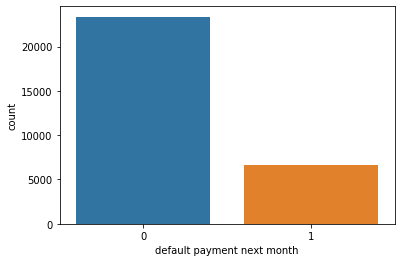

In [9]:
sns.countplot(data['default payment next month'])

#Quiz EDA and Visualization

In [10]:
target = 'default payment next month'
features_list = list(data.columns)
features_list.remove(target)

## Univariate analysis


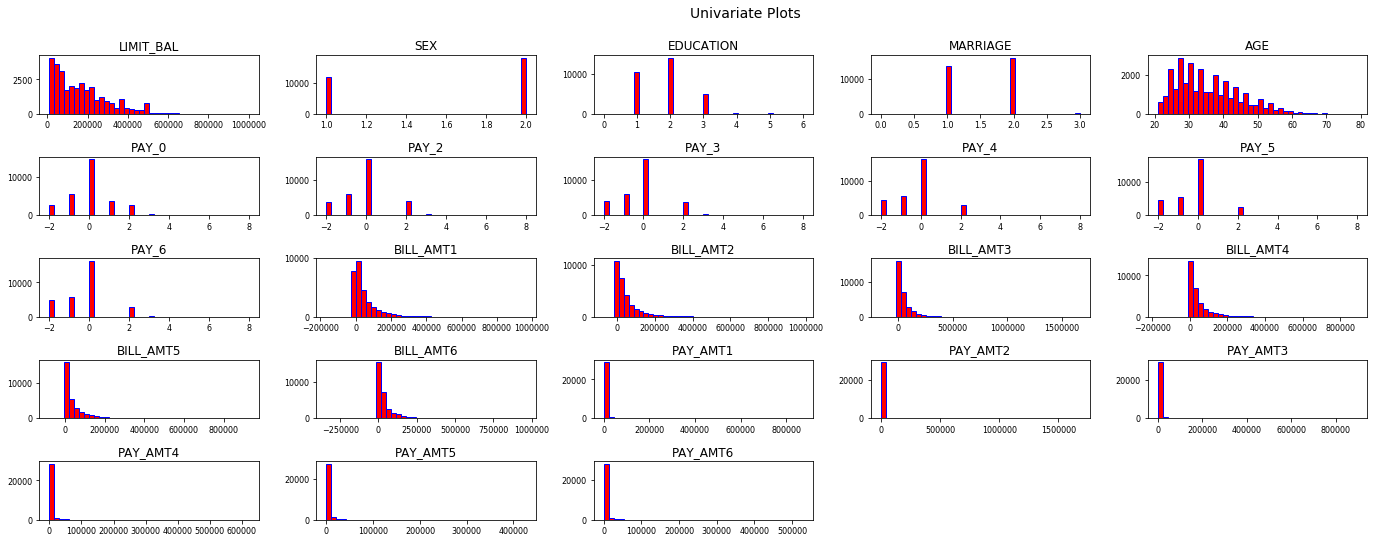

In [11]:
data[features_list].hist(bins=40, edgecolor='b', linewidth=1.0,
                          xlabelsize=8, ylabelsize=8, grid=False, 
                          figsize=(16,6), color='red')    
plt.tight_layout(rect=(0, 0, 1.2, 1.2))   
plt.suptitle('Univariate Plots', x=0.65, y=1.25, fontsize=14);  

## Bivariate analysis


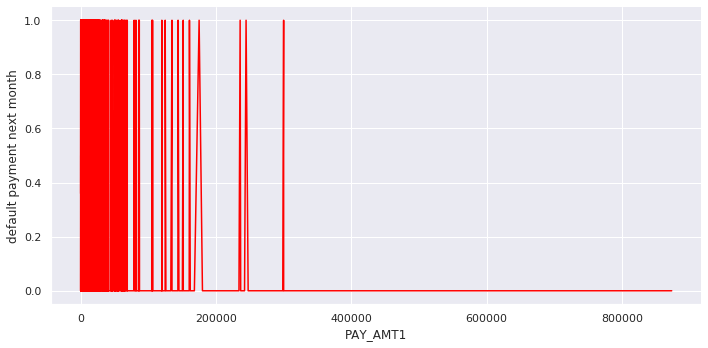

In [12]:
sns.set()
sns.relplot(data=data, x='PAY_AMT1', y=target, kind='line', height=5, aspect=2, color='red');

## Correlation analysis

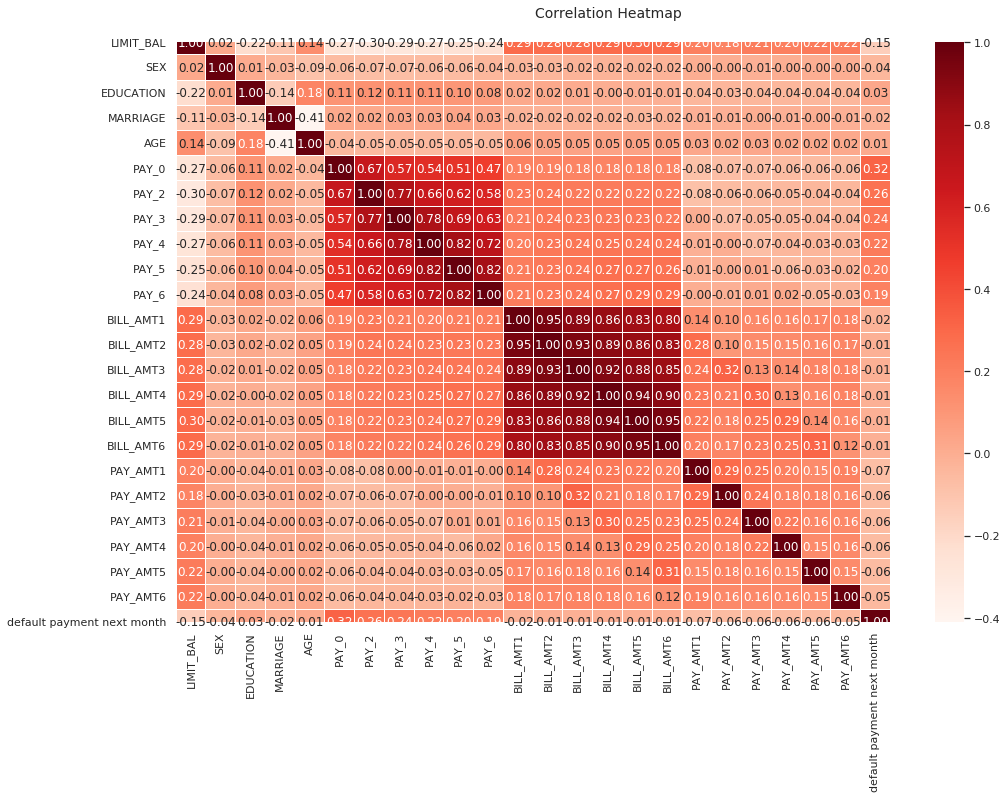

In [13]:
f, ax = plt.subplots(figsize=(16, 10))
corr = data.corr()
hm = sns.heatmap(round(corr,2), annot=True, ax=ax, cmap="Reds",fmt='.2f',
            linewidths=.05)
f.subplots_adjust(top=0.93)
t= f.suptitle('Correlation Heatmap', fontsize=14)


## Feature importance

In [14]:
x = data.iloc[:,0:-1]
y = data.iloc[:,-1]
x.shape,y.shape

((30000, 23), (30000,))

In [15]:
data.isnull().sum()

LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

## Train test split

In [16]:
from sklearn.model_selection import train_test_split as split
x_train,x_test,y_train,y_test = split(x,y,test_size=0.1,stratify=y)
x_train.shape,x_test.shape

((27000, 23), (3000, 23))

## Random forest

In [17]:
rfc = RandomForestClassifier()

In [18]:
rfc.fit(x_train,y_train)

RandomForestClassifier()

     variable  importance
5       PAY_0    0.095577
4         AGE    0.066484
11  BILL_AMT1    0.060404
0   LIMIT_BAL    0.059914
12  BILL_AMT2    0.054258
13  BILL_AMT3    0.052006
17   PAY_AMT1    0.051270
14  BILL_AMT4    0.050951
16  BILL_AMT6    0.050634
15  BILL_AMT5    0.049313


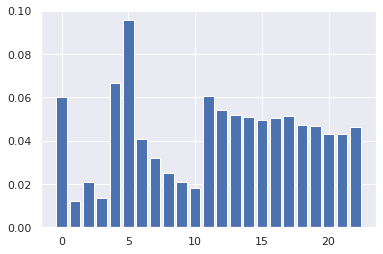

In [40]:
importance = rfc.feature_importances_
 
# for i,v in enumerate(importance):
# 	print('Feature: %0d, Score: %.5f' % (i,v))
feature_importance = pd.DataFrame()
feature_importance['variable'] = x_train.columns
feature_importance['importance'] = rfc.feature_importances_
print(feature_importance.sort_values(by='importance', ascending=False).head(10))
plt.bar([x for x in range(len(importance))], importance)
plt.show()

#### (Feature 5) PAY_0 has more importance

In [20]:
rfc.score(x_test,y_test)

0.8186666666666667

## save model

In [21]:
import pickle
pickle.dump(rfc, open("/content/drive/MyDrive/Colab Notebooks/extra assignment/rfc.pkl", 'wb'))

## LIME

In [24]:
import lime
from lime import lime_tabular

In [25]:
interpretor = lime_tabular.LimeTabularExplainer(
    training_data = np.array(x_train),
    feature_names = x_train.columns,
    mode = 'classification'
)

In [26]:
x_test.iloc[5]

LIMIT_BAL    100000
SEX               1
EDUCATION         1
MARRIAGE          2
AGE              32
PAY_0             0
PAY_2             0
PAY_3             0
PAY_4             0
PAY_5             0
PAY_6             0
BILL_AMT1     83845
BILL_AMT2     87580
BILL_AMT3     84140
BILL_AMT4     86400
BILL_AMT5     87275
BILL_AMT6     89082
PAY_AMT1       4500
PAY_AMT2       3300
PAY_AMT3       3881
PAY_AMT4       2500
PAY_AMT5       2519
PAY_AMT6       2700
Name: 27171, dtype: int64

In [27]:
exp = interpretor.explain_instance(
    data_row=x_test.iloc[5], ##new data
    predict_fn=rfc.predict_proba
)

exp.show_in_notebook(show_table=True)

/usr/local/lib/python3.7/dist-packages/sklearn/base.py:451: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  "X does not have valid feature names, but"


## Partial Dependence Plots (PD plot)

In [28]:
from pdpbox import pdp, get_dataset, info_plots

In [29]:
def plot_pdp(model, df, feature, cluster_flag=False, nb_clusters=None, lines_flag=False):
    
    # Create the data that we will plot
    pdp_goals = pdp.pdp_isolate(model=model, dataset=df, model_features=df.columns.tolist(), feature=feature)

    # plot it
    pdp.pdp_plot(pdp_goals, feature, cluster=cluster_flag, n_cluster_centers=nb_clusters, plot_lines=lines_flag)
    plt.show()

findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


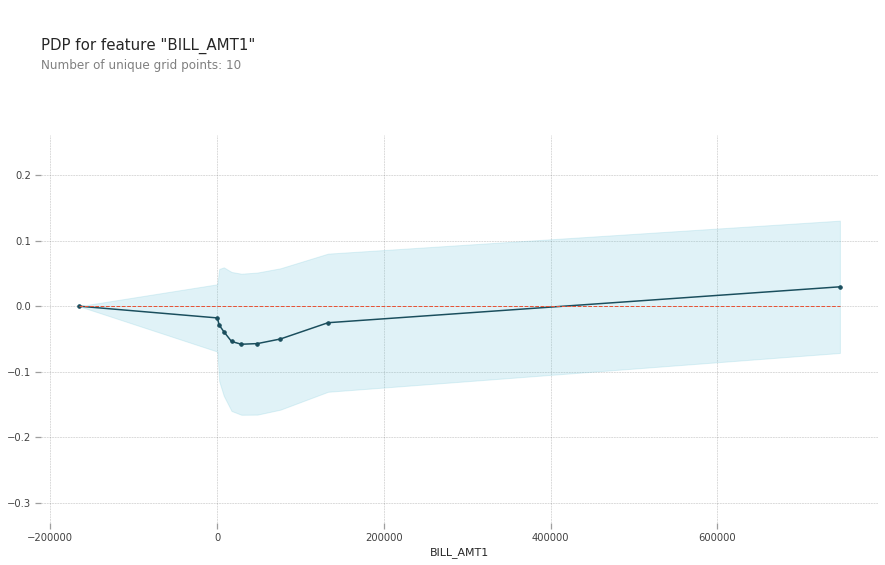

In [30]:
plot_pdp(rfc, x_train, 'BILL_AMT1')

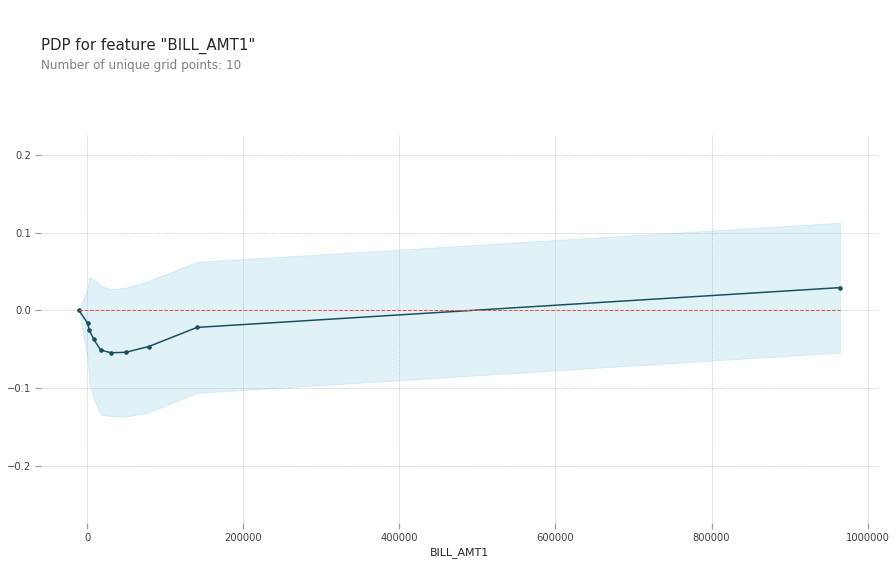

In [31]:
plot_pdp(rfc, x_test, 'BILL_AMT1')

## Bivariate Partial dependancy plot PDP

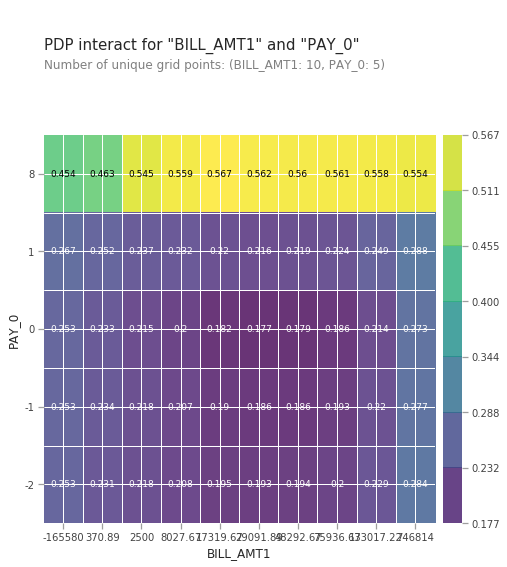

<Figure size 1728x1152 with 0 Axes>

In [39]:
features_to_plot = ['BILL_AMT1', 'PAY_0']
inter1  =  pdp.pdp_interact(model=rfc, dataset=x_train, model_features=features_list, features=features_to_plot)
pdp.pdp_interact_plot(pdp_interact_out=inter1, feature_names=features_to_plot, plot_type='grid')
plt.figure(figsize=(24,16))
plt.show()


#### We have used local interpretation along with surrogate models and PDP plots